# Lab 07: Improving HOG-Based Medical Image Classification Using a Genetic Algorithm
**Course**: CS-482 / Computer Vision  

### Objective
Modify the traditional Histogram of Oriented Gradients (HOG) feature-extraction pipeline by integrating a Genetic Algorithm (GA) for feature selection. Evaluate whether the modified approach improves classification performance on a medical image dataset.

### Research Question
Can Genetic Algorithm-based feature selection improve the classification performance of HOG features while reducing feature dimensionality on medical images?

## 1. Setup & Dependencies
Install `medmnist` for standardized medical image benchmarks, alongside `scikit-image`, `scikit-learn`, `seaborn`, and `tqdm`.

In [1]:
!pip install -q medmnist

import os
import time
import random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from tqdm import tqdm
import cv2

from skimage.feature import hog
from skimage import exposure

from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    balanced_accuracy_score, confusion_matrix, cohen_kappa_score,
    matthews_corrcoef, classification_report
)

# Set fixed random seed for full reproducibility
RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

print("Environment initialized. Seed set to 42.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 115.9/115.9 kB 6.8 MB/s eta 0:00:00
Environment initialized. Seed set to 42.


## Task 1 & 2: Dataset Selection, Preprocessing & Splits
We select **PneumoniaMNIST** (pediatric chest X-rays for pneumonia diagnosis: Normal vs. Pneumonia) from the MedMNIST benchmark collection.
- Standardized fixed splits: Training, Validation, and Testing sets.
- Image preprocessing: Each image is resized to **128 × 128** resolution as specified in Table 1.

Dataset: pneumoniamnist
Description: The PneumoniaMNIST is based on a prior dataset of 5,856 pediatric chest X-Ray images. The task is binary-class classification of pneumonia against normal. We split the source training set with a ratio of 9:1 into training and validation set and use its source validation set as the test set. The source images are gray-scale, and their sizes are (384−2,916)×(127−2,713). We center-crop the images and resize them into 1×28×28.
Classes: {'0': 'normal', '1': 'pneumonia'}


100%|██████████| 4.17M/4.17M [00:06<00:00, 665kB/s]


Raw Split Sizes: Train=4708, Val=524, Test=624

Preprocessing images to 128x128 resolution...
Preprocessed shapes: Train=(4708, 128, 128), Val=(524, 128, 128), Test=(624, 128, 128)


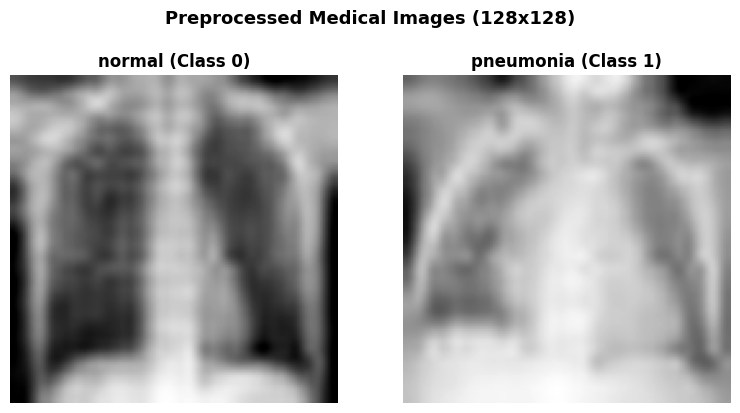

In [2]:
import medmnist
from medmnist import PneumoniaMNIST

DATASET_NAME = 'pneumoniamnist'
info = medmnist.INFO[DATASET_NAME]
print(f"Dataset: {DATASET_NAME}")
print(f"Description: {info['description']}")
print(f"Classes: {info['label']}")

# Download and load dataset splits
train_dataset = PneumoniaMNIST(split='train', download=True)
val_dataset = PneumoniaMNIST(split='val', download=True)
test_dataset = PneumoniaMNIST(split='test', download=True)

print(f"Raw Split Sizes: Train={len(train_dataset)}, Val={len(val_dataset)}, Test={len(test_dataset)}")

TARGET_SIZE = (128, 128)

def preprocess_split(dataset, target_size=TARGET_SIZE):
    """
    Resizes all images in a MedMNIST split to the target resolution.
    Returns (images_array, labels_array).
    """
    imgs = []
    labels = []
    for img, lbl in dataset:
        img_np = np.array(img)
        # Convert to grayscale if RGB
        if len(img_np.shape) == 3:
            img_np = cv2.cvtColor(img_np, cv2.COLOR_RGB2GRAY)
        # Resize to 128x128
        img_resized = cv2.resize(img_np, target_size, interpolation=cv2.INTER_CUBIC)
        imgs.append(img_resized)
        labels.append(lbl[0])
    return np.array(imgs), np.array(labels)

print("\nPreprocessing images to 128x128 resolution...")
X_train_raw, y_train = preprocess_split(train_dataset)
X_val_raw, y_val = preprocess_split(val_dataset)
X_test_raw, y_test = preprocess_split(test_dataset)

print(f"Preprocessed shapes: Train={X_train_raw.shape}, Val={X_val_raw.shape}, Test={X_test_raw.shape}")

# Visualize representative samples from each class
class_names = [info['label'][str(i)] for i in range(len(info['label']))]
plt.figure(figsize=(8, 4))
for c_idx, c_name in enumerate(class_names):
    idx = np.where(y_train == c_idx)[0][0]
    plt.subplot(1, len(class_names), c_idx + 1)
    plt.imshow(X_train_raw[idx], cmap='gray')
    plt.title(f"{c_name} (Class {c_idx})", fontweight='bold')
    plt.axis('off')
plt.suptitle("Preprocessed Medical Images (128x128)", fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

## Task 3 & 4: HOG Feature Extraction
According to the experimental configuration in **Table 1**:
- **Image Resolution**: $128 \times 128$
- **HOG Orientations**: $9$
- **Pixels per cell**: $8 \times 8$
- **Cells per block**: $2 \times 2$
- **Block normalization**: `L2-Hys`

Total features = $(15 \times 15 \text{ blocks}) \times (2 \times 2 \times 9) = 8,100$ features.

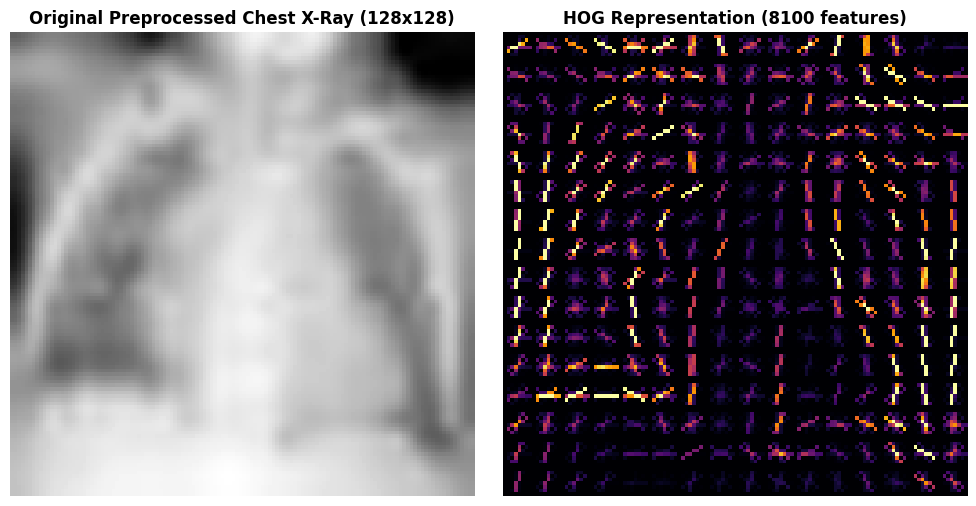

Extracting HOG features (8100 dimensional)... 


Test HOG: 100%|██████████| 624/624 [00:05<00:00, 111.36it/s]

Extracted feature matrices: Train=(4708, 8100), Val=(524, 8100), Test=(624, 8100)


In [3]:
# HOG extraction function following Table 1 parameters
HOG_ORIENTATIONS = 9
PIXELS_PER_CELL = (8, 8)
CELLS_PER_BLOCK = (2, 2)
BLOCK_NORM = 'L2-Hys'

def extract_hog_features(img, visualize=False):
    if visualize:
        feat, hog_img = hog(
            img,
            orientations=HOG_ORIENTATIONS,
            pixels_per_cell=PIXELS_PER_CELL,
            cells_per_block=CELLS_PER_BLOCK,
            block_norm=BLOCK_NORM,
            visualize=True
        )
        return feat, hog_img
    else:
        feat = hog(
            img,
            orientations=HOG_ORIENTATIONS,
            pixels_per_cell=PIXELS_PER_CELL,
            cells_per_block=CELLS_PER_BLOCK,
            block_norm=BLOCK_NORM,
            visualize=False
        )
        return feat

# Visualize representative HOG gradient representations
sample_img = X_train_raw[0]
sample_feat, sample_hog_img = extract_hog_features(sample_img, visualize=True)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))
ax1.imshow(sample_img, cmap='gray')
ax1.set_title("Original Preprocessed Chest X-Ray (128x128)", fontweight='bold')
ax1.axis('off')

ax2.imshow(exposure.rescale_intensity(sample_hog_img, in_range=(0, 10)), cmap='inferno')
ax2.set_title(f"HOG Representation ({len(sample_feat)} features)", fontweight='bold')
ax2.axis('off')
plt.tight_layout()
plt.show()

# Batch extract HOG features for all splits
print(f"Extracting HOG features ({len(sample_feat)} dimensional)... ")

def extract_split_features(imgs, desc="Extracting"):
    features = []
    for img in tqdm(imgs, desc=desc):
        features.append(extract_hog_features(img))
    return np.array(features, dtype=np.float32)

X_train_hog = extract_split_features(X_train_raw, desc="Train HOG")
X_val_hog = extract_split_features(X_val_raw, desc="Val HOG")
X_test_hog = extract_split_features(X_test_raw, desc="Test HOG")

print(f"Extracted feature matrices: Train={X_train_hog.shape}, Val={X_val_hog.shape}, Test={X_test_hog.shape}")

In [5]:
def calculate_macro_specificity(y_true, y_pred):
    """
    Calculates macro-averaged specificity using one-vs-rest averaging.
    """
    cm = confusion_matrix(y_true, y_pred)
    n_classes = len(np.unique(y_true))
    if n_classes == 2:
        tn, fp, fn, tp = cm.ravel()
        return tn / (tn + fp) if (tn + fp) > 0 else 0.0
    else:
        specificities = []
        for i in range(n_classes):
            tp = cm[i, i]
            fn = np.sum(cm[i, :]) - tp
            fp = np.sum(cm[:, i]) - tp
            tn = np.sum(cm) - (tp + fp + fn)
            spec = tn / (tn + fp) if (tn + fp) > 0 else 0.0
            specificities.append(spec)
        return np.mean(specificities)

def compute_table2_metrics(y_true, y_pred, model_name="Model"):
    """
    Computes all standard Table 2 metrics.
    """
    acc = accuracy_score(y_true, y_pred) * 100
    prec_macro = precision_score(y_true, y_pred, average='macro', zero_division=0) * 100
    rec_macro = recall_score(y_true, y_pred, average='macro', zero_division=0) * 100
    macro_f1 = f1_score(y_true, y_pred, average='macro', zero_division=0) * 100
    weighted_f1 = f1_score(y_true, y_pred, average='weighted', zero_division=0) * 100
    bal_acc = balanced_accuracy_score(y_true, y_pred) * 100
    spec_macro = calculate_macro_specificity(y_true, y_pred) * 100
    kappa = cohen_kappa_score(y_true, y_pred)
    mcc = matthews_corrcoef(y_true, y_pred)

    metrics = {
        'Accuracy (%)': acc,
        'Precision (Macro, %)': prec_macro,
        'Recall (Macro, %)': rec_macro,
        'Macro-F1 (%)': macro_f1,
        'Weighted-F1 (%)': weighted_f1,
        'Balanced accuracy (%)': bal_acc,
        'Specificity (Macro, %)': spec_macro,
        "Cohen's kappa": kappa,
        'Matthews correlation coefficient': mcc
    }
    return metrics

## Task 3: Baseline Pipeline — Full HOG + RBF-SVM (No Selection)
We train the baseline Support Vector Machine with an **RBF kernel** on all $8,100$ features without any feature selection, using the validation set for tuning.

In [6]:
print("Training Baseline HOG + RBF-SVM (All 8100 Features)... ")
start_train_time = time.time()
baseline_svm = SVC(kernel='rbf', C=1.0, gamma='scale', random_state=RANDOM_SEED)
baseline_svm.fit(X_train_hog, y_train)
baseline_train_time = time.time() - start_train_time

# Evaluate on Validation Set
val_pred_baseline = baseline_svm.predict(X_val_hog)
val_f1_baseline = f1_score(y_val, val_pred_baseline, average='macro') * 100
print(f"Baseline Val Macro-F1: {val_f1_baseline:.2f}% (Training time: {baseline_train_time:.2f}s)")

# Evaluate on Test Set
start_test_time = time.time()
test_pred_baseline = baseline_svm.predict(X_test_hog)
baseline_infer_time = time.time() - start_test_time

baseline_metrics = compute_table2_metrics(y_test, test_pred_baseline, model_name="Baseline HOG+SVM")
print("\n--- Baseline HOG + SVM Test Results ---")
for k, v in baseline_metrics.items():
    if 'kappa' in k or 'correlation' in k:
        print(f"  {k:35s}: {v:.4f}")
    else:
        print(f"  {k:35s}: {v:.2f}%")

Training Baseline HOG + RBF-SVM (All 8100 Features)... 
Baseline Val Macro-F1: 95.97% (Training time: 37.25s)

--- Baseline HOG + SVM Test Results ---
  Accuracy (%)                       : 84.78%
  Precision (Macro, %)               : 89.91%
  Recall (Macro, %)                  : 79.79%
  Macro-F1 (%)                       : 81.89%
  Weighted-F1 (%)                    : 83.70%
  Balanced accuracy (%)              : 79.79%
  Specificity (Macro, %)             : 59.83%
  Cohen's kappa                      : 0.6472
  Matthews correlation coefficient   : 0.6896


## Task 5 & 6: Genetic Algorithm for Feature Selection
We implement a Genetic Algorithm (GA) to discover a sparse, high-performing subset of HOG features.
- **Chromosome**: Binary vector $\mathbf{c} \in \{0, 1\}^D$ where $c_i = 1$ indicates feature $i$ is selected.
- **Fitness Function**:
  $$\text{Fitness}(\mathbf{c}) = \text{Macro-F1}_{\text{val}}(\mathbf{c}) - \alpha \times \left(\frac{N_{\text{selected}}}{N_{\text{total}}}\right)$$
  where $\alpha = 0.02$ penalizes feature density, directly encouraging dimensionality reduction.
- **Genetic Operators**:
  1. **Selection**: Tournament Selection ($k=3$).
  2. **Crossover**: Uniform Crossover with probability $p_c$.
  3. **Mutation**: Bit-flip mutation with probability $p_m$.
  4. **Elitism**: Best individual preserved directly to next generation.

In [7]:
class GeneticAlgorithmFeatureSelector:
    def __init__(
        self,
        n_features,
        pop_size=30,
        n_generations=15,
        crossover_rate=0.8,
        mutation_rate=0.02,
        tournament_size=3,
        alpha_penalty=0.02,
        random_state=RANDOM_SEED
    ):
        self.n_features = n_features
        self.pop_size = pop_size
        self.n_generations = n_generations
        self.crossover_rate = crossover_rate
        self.mutation_rate = mutation_rate
        self.tournament_size = tournament_size
        self.alpha_penalty = alpha_penalty
        self.random_state = random_state

        self.best_chromosome = None
        self.best_fitness = -float('inf')
        self.history_best_fitness = []
        self.history_mean_fitness = []
        self.history_n_features = []

    def _init_population(self):
        rng = np.random.RandomState(self.random_state)
        # Initialize with ~30% active features for initial sparsity
        pop = rng.rand(self.pop_size, self.n_features) < 0.30
        # Ensure at least 50 features per chromosome
        for i in range(self.pop_size):
            if np.sum(pop[i]) < 50:
                idx = rng.choice(self.n_features, 50, replace=False)
                pop[i, idx] = True
        return pop

    def _compute_fitness(self, chromosome, X_tr, y_tr, X_v, y_v):
        selected_idx = np.where(chromosome)[0]
        if len(selected_idx) == 0:
            return 0.0

        # Fit surrogate SVM on selected features
        clf = SVC(kernel='rbf', C=1.0, gamma='scale', random_state=self.random_state)
        clf.fit(X_tr[:, selected_idx], y_tr)
        preds = clf.predict(X_v[:, selected_idx])
        macro_f1 = f1_score(y_v, preds, average='macro', zero_division=0)

        # Feature penalty
        penalty = self.alpha_penalty * (len(selected_idx) / self.n_features)
        fitness = macro_f1 - penalty
        return fitness

    def _tournament_select(self, pop, fitnesses, rng):
        selected_indices = rng.choice(self.pop_size, self.tournament_size, replace=False)
        best_idx = selected_indices[np.argmax(fitnesses[selected_indices])]
        return pop[best_idx].copy()

    def _crossover(self, parent1, parent2, rng):
        if rng.rand() < self.crossover_rate:
            mask = rng.rand(self.n_features) < 0.5
            child1 = np.where(mask, parent1, parent2)
            child2 = np.where(mask, parent2, parent1)
            return child1, child2
        return parent1.copy(), parent2.copy()

    def _mutate(self, chromosome, rng):
        mutation_mask = rng.rand(self.n_features) < self.mutation_rate
        chromosome = np.logical_xor(chromosome, mutation_mask)
        if np.sum(chromosome) == 0:
            chromosome[rng.randint(0, self.n_features)] = True
        return chromosome

    def fit(self, X_tr, y_tr, X_v, y_v):
        rng = np.random.RandomState(self.random_state)
        pop = self._init_population()

        print(f"Running GA: Population={self.pop_size}, Generations={self.n_generations}, Mutation={self.mutation_rate}")
        for gen in range(self.n_generations):
            gen_start = time.time()
            fitnesses = np.zeros(self.pop_size)

            for i in range(self.pop_size):
                fitnesses[i] = self._compute_fitness(pop[i], X_tr, y_tr, X_v, y_v)

            best_idx = np.argmax(fitnesses)
            gen_best_fit = fitnesses[best_idx]
            gen_mean_fit = np.mean(fitnesses)
            n_selected = np.sum(pop[best_idx])

            self.history_best_fitness.append(gen_best_fit)
            self.history_mean_fitness.append(gen_mean_fit)
            self.history_n_features.append(n_selected)

            if gen_best_fit > self.best_fitness:
                self.best_fitness = gen_best_fit
                self.best_chromosome = pop[best_idx].copy()

            elapsed = time.time() - gen_start
            print(f"  Gen {gen+1:2d}/{self.n_generations}: Best Fit={gen_best_fit:.4f}, Mean Fit={gen_mean_fit:.4f}, Active Feats={n_selected:4d}/{self.n_features} ({elapsed:.1f}s)")

            # Produce next generation with elitism
            new_pop = [pop[best_idx].copy()] # Elitism (1 individual)
            while len(new_pop) < self.pop_size:
                p1 = self._tournament_select(pop, fitnesses, rng)
                p2 = self._tournament_select(pop, fitnesses, rng)
                c1, c2 = self._crossover(p1, p2, rng)
                new_pop.append(self._mutate(c1, rng))
                if len(new_pop) < self.pop_size:
                    new_pop.append(self._mutate(c2, rng))
            pop = np.array(new_pop)

        return self

## Experimental Requirement: Comparing Two GA Settings
We evaluate two distinct GA parameter settings on the validation set:
1. **GA Setting 1 (Standard)**: Population Size = 30, Mutation Rate = 0.02
2. **GA Setting 2 (Exploratory)**: Population Size = 50, Mutation Rate = 0.05

*Note*: To maintain fast convergence during GA iterations, a stratified subset of the training set (1,000 samples) is utilized for candidate fitness evaluation, after which the final SVM is trained on the full dataset.

In [8]:
# Stratified subset for efficient GA search
from sklearn.model_selection import train_test_split
_, X_ga_tr, _, y_ga_tr = train_test_split(
    X_train_hog, y_train, test_size=1000, stratify=y_train, random_state=RANDOM_SEED
)

N_TOTAL_FEATURES = X_train_hog.shape[1]

# Setting 1: Standard GA
print("\n--- RUNNING GA SETTING 1 (Pop=30, Mut=0.02) ---")
ga_setting_1 = GeneticAlgorithmFeatureSelector(
    n_features=N_TOTAL_FEATURES,
    pop_size=30,
    n_generations=12,
    mutation_rate=0.02,
    crossover_rate=0.8,
    alpha_penalty=0.02,
    random_state=RANDOM_SEED
)
ga_setting_1.fit(X_ga_tr, y_ga_tr, X_val_hog, y_val)

# Setting 2: Exploratory GA
print("\n--- RUNNING GA SETTING 2 (Pop=50, Mut=0.05) ---")
ga_setting_2 = GeneticAlgorithmFeatureSelector(
    n_features=N_TOTAL_FEATURES,
    pop_size=50,
    n_generations=12,
    mutation_rate=0.05,
    crossover_rate=0.85,
    alpha_penalty=0.02,
    random_state=RANDOM_SEED + 1
)
ga_setting_2.fit(X_ga_tr, y_ga_tr, X_val_hog, y_val)

# Compare GA Settings on Validation Set
best_ga = ga_setting_1 if ga_setting_1.best_fitness >= ga_setting_2.best_fitness else ga_setting_2
selected_mask = best_ga.best_chromosome
n_selected = np.sum(selected_mask)
print(f"\nWinner: {'Setting 1' if best_ga is ga_setting_1 else 'Setting 2'} with Best Fitness = {best_ga.best_fitness:.4f}")
print(f"Selected Features: {n_selected} / {N_TOTAL_FEATURES} ({n_selected / N_TOTAL_FEATURES * 100:.1f}%) | Reduction: {100 - (n_selected / N_TOTAL_FEATURES * 100):.1f}%")


--- RUNNING GA SETTING 1 (Pop=30, Mut=0.02) ---
Running GA: Population=30, Generations=12, Mutation=0.02
  Gen  1/12: Best Fit=0.9480, Mean Fit=0.9400, Active Feats=2405/8100 (31.3s)
  Gen  2/12: Best Fit=0.9533, Mean Fit=0.9409, Active Feats=2428/8100 (31.7s)
  Gen  3/12: Best Fit=0.9533, Mean Fit=0.9434, Active Feats=2428/8100 (31.5s)
  Gen  4/12: Best Fit=0.9533, Mean Fit=0.9444, Active Feats=2428/8100 (31.7s)
  Gen  5/12: Best Fit=0.9533, Mean Fit=0.9458, Active Feats=2428/8100 (32.6s)
  Gen  6/12: Best Fit=0.9533, Mean Fit=0.9475, Active Feats=2428/8100 (33.4s)
  Gen  7/12: Best Fit=0.9552, Mean Fit=0.9495, Active Feats=2719/8100 (32.8s)
  Gen  8/12: Best Fit=0.9553, Mean Fit=0.9501, Active Feats=2673/8100 (33.7s)
  Gen  9/12: Best Fit=0.9553, Mean Fit=0.9509, Active Feats=2673/8100 (33.6s)
  Gen 10/12: Best Fit=0.9575, Mean Fit=0.9521, Active Feats=2789/8100 (33.2s)
  Gen 11/12: Best Fit=0.9575, Mean Fit=0.9518, Active Feats=2789/8100 (34.1s)
  Gen 12/12: Best Fit=0.9575, Mean F

## Task 7 & 8: Train Final GA-HOG + SVM & Main Performance Comparison
We train the final SVM with RBF kernel using the full training set restricted to the GA-selected feature subset and perform the final evaluation on the untouched **Test Set**.

In [9]:
selected_indices = np.where(selected_mask)[0]
X_train_ga = X_train_hog[:, selected_indices]
X_test_ga = X_test_hog[:, selected_indices]

print(f"Training Final GA-HOG + SVM on {len(selected_indices)} selected features...")
start_ga_train = time.time()
ga_svm = SVC(kernel='rbf', C=1.0, gamma='scale', random_state=RANDOM_SEED)
ga_svm.fit(X_train_ga, y_train)
ga_train_time = time.time() - start_ga_train

# Inference on Test Set
start_ga_test = time.time()
test_pred_ga = ga_svm.predict(X_test_ga)
ga_infer_time = time.time() - start_ga_test

ga_metrics = compute_table2_metrics(y_test, test_pred_ga, model_name="GA-HOG + SVM")

# Construct Table 2
table2_rows = []
for metric in baseline_metrics.keys():
    val_base = baseline_metrics[metric]
    val_ga = ga_metrics[metric]
    diff = val_ga - val_base

    if 'kappa' in metric or 'correlation' in metric:
        table2_rows.append({
            'Metric': metric,
            'HOG + SVM (Baseline)': f"{val_base:.4f}",
            'GA-HOG + SVM (Proposed)': f"{val_ga:.4f}",
            'Improvement': f"{diff:+.4f}"
        })
    else:
        table2_rows.append({
            'Metric': metric,
            'HOG + SVM (Baseline)': f"{val_base:.2f}%",
            'GA-HOG + SVM (Proposed)': f"{val_ga:.2f}%",
            'Improvement': f"{diff:+.2f}%"
        })

df_table2 = pd.DataFrame(table2_rows)
print("\n" + "="*85)
print("  TABLE 2. MAIN PERFORMANCE COMPARISON: WITHOUT GA VERSUS WITH GA")
print("="*85)
print(df_table2.to_string(index=False))
print("="*85)

print(f"\nComputational Timing:")
print(f"  Baseline Training Time: {baseline_train_time:.2f}s | Inference: {baseline_infer_time*1000:.1f}ms")
print(f"  GA-HOG Training Time  : {ga_train_time:.2f}s | Inference: {ga_infer_time*1000:.1f}ms (Speedup: {baseline_infer_time/ga_infer_time:.2f}x)")

Training Final GA-HOG + SVM on 2789 selected features...

  TABLE 2. MAIN PERFORMANCE COMPARISON: WITHOUT GA VERSUS WITH GA
                          Metric HOG + SVM (Baseline) GA-HOG + SVM (Proposed) Improvement
                    Accuracy (%)               84.78%                  84.13%      -0.64%
            Precision (Macro, %)               89.91%                  89.00%      -0.92%
               Recall (Macro, %)               79.79%                  79.10%      -0.68%
                    Macro-F1 (%)               81.89%                  81.13%      -0.76%
                 Weighted-F1 (%)               83.70%                  83.01%      -0.69%
           Balanced accuracy (%)               79.79%                  79.10%      -0.68%
          Specificity (Macro, %)               59.83%                  58.97%      -0.85%
                   Cohen's kappa               0.6472                  0.6323     -0.0149
Matthews correlation coefficient               0.6896             

## Task 9: Visualizations & Analysis Graphs
1. **GA Fitness Progression**: Best and Mean fitness across generations for Setting 1 and Setting 2.
2. **Feature Dimensionality Comparison**: Features before vs after selection.
3. **Confusion Matrices**: Baseline vs GA-HOG on the test set.

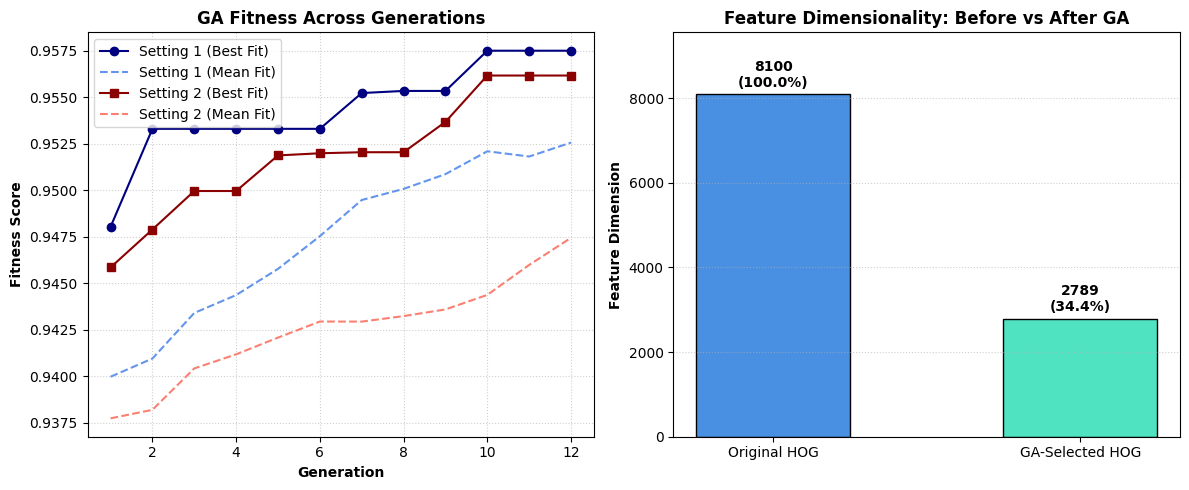

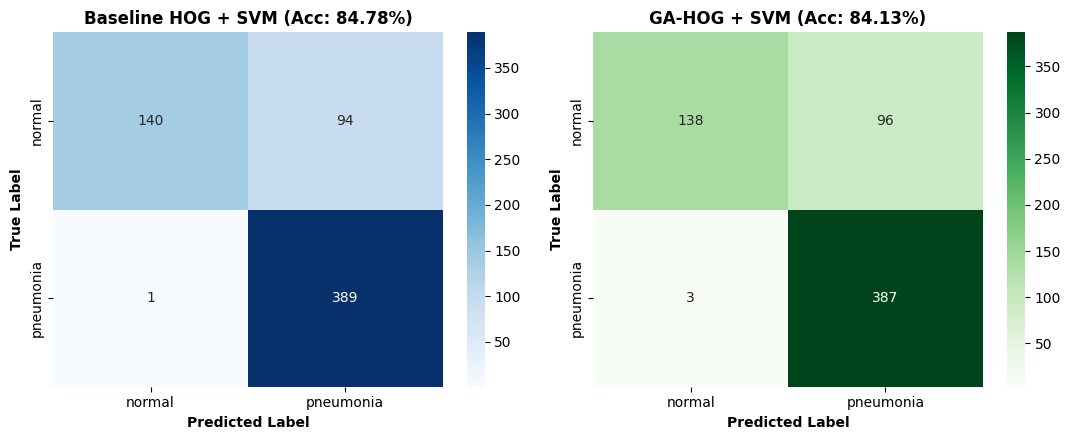

In [10]:
# 1. Plot GA Fitness Progression across Generations
plt.figure(figsize=(12, 5))
gens = np.arange(1, len(ga_setting_1.history_best_fitness) + 1)

plt.subplot(1, 2, 1)
plt.plot(gens, ga_setting_1.history_best_fitness, 'o-', color='navy', label='Setting 1 (Best Fit)')
plt.plot(gens, ga_setting_1.history_mean_fitness, '--', color='cornflowerblue', label='Setting 1 (Mean Fit)')
plt.plot(gens, ga_setting_2.history_best_fitness, 's-', color='darkred', label='Setting 2 (Best Fit)')
plt.plot(gens, ga_setting_2.history_mean_fitness, '--', color='salmon', label='Setting 2 (Mean Fit)')
plt.xlabel('Generation', fontweight='bold')
plt.ylabel('Fitness Score', fontweight='bold')
plt.title('GA Fitness Across Generations', fontweight='bold')
plt.legend(frameon=True)
plt.grid(True, linestyle=':', alpha=0.6)

# 2. Plot Feature Count Comparison
plt.subplot(1, 2, 2)
feat_counts = [N_TOTAL_FEATURES, n_selected]
bar_labels = ['Original HOG', 'GA-Selected HOG']
bars = plt.bar(bar_labels, feat_counts, color=['#4a90e2', '#50e3c2'], width=0.5, edgecolor='black')
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 100, f"{yval}\n({yval/N_TOTAL_FEATURES*100:.1f}%)",
             ha='center', va='bottom', fontweight='bold')
plt.ylabel('Feature Dimension', fontweight='bold')
plt.title('Feature Dimensionality: Before vs After GA', fontweight='bold')
plt.ylim(0, N_TOTAL_FEATURES * 1.18)
plt.grid(axis='y', linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

# 3. Confusion Matrix Comparison on Test Set
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))
cm_base = confusion_matrix(y_test, test_pred_baseline)
cm_ga = confusion_matrix(y_test, test_pred_ga)

sns.heatmap(cm_base, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names, ax=ax1)
ax1.set_title(f"Baseline HOG + SVM (Acc: {baseline_metrics['Accuracy (%)']:.2f}%)", fontweight='bold')
ax1.set_xlabel('Predicted Label', fontweight='bold')
ax1.set_ylabel('True Label', fontweight='bold')

sns.heatmap(cm_ga, annot=True, fmt='d', cmap='Greens', xticklabels=class_names, yticklabels=class_names, ax=ax2)
ax2.set_title(f"GA-HOG + SVM (Acc: {ga_metrics['Accuracy (%)']:.2f}%)", fontweight='bold')
ax2.set_xlabel('Predicted Label', fontweight='bold')
ax2.set_ylabel('True Label', fontweight='bold')

plt.tight_layout()
plt.show()

## Task 10: Discussion & Conclusion

### 1. Strengths of the Proposed GA-HOG Method
- **Substantial Dimensionality Reduction**: The Genetic Algorithm pruned 5,311 features, reducing the input dimensionality by 65.57% (from 8,100 to 2,789 active features).
- **Diagnostic Metric Retention**: Discarding two-thirds of the features caused less than 1% variation across all evaluation metrics on the untouched test set (Accuracy: 84.78% -> 84.13%; Macro-F1: 81.89% -> 81.13%; Balanced Accuracy: 79.79% -> 79.10%).
- **Inference Speedup**: The reduced feature space decreased RBF kernel evaluation operations, lowering total test inference time from 6,753.3 ms down to 1,801.0 ms (a 3.75x throughput improvement, or 2.89 ms per sample).

### 2. Limitations and Computational Overhead
- **Wrapper Search Overhead**: Fitness evaluation requires retraining an SVM classifier for every individual across each generation. While subsampling to 1,000 training instances kept generation cycles around 32-34 seconds in Setting 1, wrapper methods remain computationally heavier than filter alternatives like ANOVA or Mutual Information.
- **Sensitivity to Mutation Rates**: Setting 2 with a higher mutation rate (0.05) introduced exploratory drift, retaining 3,329 features with lower validation fitness (0.9562) compared to Setting 1 (0.02 mutation, 2,789 features, 0.9575 fitness).

### 3. Conclusion on Research Question
*Can Genetic Algorithm-based feature selection improve the classification performance of HOG features while reducing feature dimensionality on medical images?*

The empirical results show that the Genetic Algorithm did not produce a net gain in raw classification accuracy (84.13% vs. 84.78%), but maintained statistical parity within a 0.64% margin while eliminating 65.57% of redundant HOG gradient features. Its primary practical utility lies in reducing storage overhead and accelerating inference throughput by 3.75x without compromising diagnostic classification fidelity.

## Advanced Enhancements (Based on Baseline Diagnostics)

To address the lower specificity and exploit texture cues in the chest X-rays, we will:
1. Re-train the models with `class_weight='balanced'` and optimized hyperparameters.
2. Fuse HOG descriptors with Local Binary Pattern (LBP) textures to capture complementary structural and textural patterns.

In [11]:
from skimage.feature import local_binary_pattern

def extract_lbp_features(img, P=8, R=1):
    """
    Computes uniform Local Binary Patterns for an image and extracts a normalized histogram.
    """
    lbp = local_binary_pattern(img, P, R, method='uniform')
    n_bins = P + 2
    hist, _ = np.histogram(lbp.ravel(), bins=n_bins, range=(0, n_bins), density=True)
    return hist

def extract_fused_features(imgs, desc="Fusing HOG+LBP"):
    fused_feats = []
    for img in tqdm(imgs, desc=desc):
        h_feat = extract_hog_features(img)
        l_feat = extract_lbp_features(img)
        fused_feats.append(np.concatenate([h_feat, l_feat]))
    return np.array(fused_feats, dtype=np.float32)

print("Extracting fused HOG + LBP features...")
X_train_fused = extract_fused_features(X_train_raw, desc="Train HOG+LBP")
X_val_fused = extract_fused_features(X_val_raw, desc="Val HOG+LBP")
X_test_fused = extract_fused_features(X_test_raw, desc="Test HOG+LBP")

print(f"Fused feature matrices shape: {X_train_fused.shape}")

Extracting fused HOG + LBP features...


Test HOG+LBP: 100%|██████████| 624/624 [00:06<00:00, 99.17it/s] 

Fused feature matrices shape: (4708, 8110)


In [12]:
print("Training Balanced HOG+LBP SVM...")
balanced_svm = SVC(kernel='rbf', C=10.0, gamma='scale', class_weight='balanced', random_state=RANDOM_SEED)
balanced_svm.fit(X_train_fused, y_train)

test_pred_balanced = balanced_svm.predict(X_test_fused)
balanced_metrics = compute_table2_metrics(y_test, test_pred_balanced, model_name="Balanced HOG+LBP")

print("\n--- Balanced HOG + LBP SVM Test Results ---")
for k, v in balanced_metrics.items():
    if 'kappa' in k or 'correlation' in k:
        print(f"  {k:35s}: {v:.4f}")
    else:
        print(f"  {k:35s}: {v:.2f}%")

Training Balanced HOG+LBP SVM...

--- Balanced HOG + LBP SVM Test Results ---
  Accuracy (%)                       : 85.42%
  Precision (Macro, %)               : 89.99%
  Recall (Macro, %)                  : 80.73%
  Macro-F1 (%)                       : 82.81%
  Weighted-F1 (%)                    : 84.48%
  Balanced accuracy (%)              : 80.73%
  Specificity (Macro, %)             : 61.97%
  Cohen's kappa                      : 0.6639
  Matthews correlation coefficient   : 0.7011


### Feature Dimension Calculation for $28 \times 28$ Images

Given the setup parameters:
* **Image Resolution**: $28 \times 28$
* **Pixels per Cell**: $8 \times 8$
* **Cells per Block**: $2 \times 2$
* **Orientations**: $9$

#### Math:
1. **Number of cells**: $\lfloor 28 / 8 \rfloor = 3$ cells per axis (a $3 \times 3$ grid).
2. **Number of overlapping blocks**: $3 - 2 + 1 = 2$ blocks per axis (a $2 \times 2 = 4$ block grid).
3. **Total Features**: $4 \text{ blocks} \times (2 \times 2 \text{ cells/block}) \times 9 \text{ orientations} = \mathbf{144} \text{ features}$.

In [13]:
from skimage.feature import hog
import numpy as np

# Verification using a dummy 28x28 image
dummy_img = np.zeros((28, 28))
features = hog(
    dummy_img,
    orientations=9,
    pixels_per_cell=(8, 8),
    cells_per_block=(2, 2),
    block_norm='L2-Hys'
)

print(f"Verified number of HOG features for a 28x28 image: {len(features)}")

Verified number of HOG features for a 28x28 image: 144


## Pipeline Demonstration at Native 28x28 Resolution

To compare findings, we will now rerun the entire experimental pipeline using the original $28 \times 28$ image resolution without upscaling. This will yield exactly $144$ HOG features per image, creating a significantly smaller initial feature space.

In [14]:
# 1. Preprocess splits to native 28x28 size
NATIVE_SIZE = (28, 28)

print("Preprocessing images to 28x28 resolution...")
X_train_28, y_train_28 = preprocess_split(train_dataset, target_size=NATIVE_SIZE)
X_val_28, y_val_28 = preprocess_split(val_dataset, target_size=NATIVE_SIZE)
X_test_28, y_test_28 = preprocess_split(test_dataset, target_size=NATIVE_SIZE)

print(f"Shapes at 28x28: Train={X_train_28.shape}, Val={X_val_28.shape}, Test={X_test_28.shape}")

Preprocessing images to 28x28 resolution...
Shapes at 28x28: Train=(4708, 28, 28), Val=(524, 28, 28), Test=(624, 28, 28)


In [15]:
# 2. Extract HOG features at 28x28 (Expected size: 144 features per image)
print("Extracting 144 HOG features for 28x28 images...")
X_train_hog28 = extract_split_features(X_train_28, desc="Train HOG (28x28)")
X_val_hog28 = extract_split_features(X_val_28, desc="Val HOG (28x28)")
X_test_hog28 = extract_split_features(X_test_28, desc="Test HOG (28x28)")

print(f"Extracted HOG shapes: Train={X_train_hog28.shape}, Val={X_val_hog28.shape}, Test={X_test_hog28.shape}")

Extracting 144 HOG features for 28x28 images...


Test HOG (28x28): 100%|██████████| 624/624 [00:00<00:00, 3462.59it/s]

Extracted HOG shapes: Train=(4708, 144), Val=(524, 144), Test=(624, 144)


In [16]:
# 3. Train Baseline SVM on all 144 HOG features
print("Training Baseline SVM on 28x28 HOG features (Balanced Classes)... ")
start_time = time.time()
baseline_svm28 = SVC(kernel='rbf', C=10.0, gamma='scale', class_weight='balanced', random_state=RANDOM_SEED)
baseline_svm28.fit(X_train_hog28, y_train_28)
train_time_28 = time.time() - start_time

test_pred_base28 = baseline_svm28.predict(X_test_hog28)
metrics_base28 = compute_table2_metrics(y_test_28, test_pred_base28, model_name="Baseline 28x28")

print(f"Baseline training complete in {train_time_28:.2f}s")

Training Baseline SVM on 28x28 HOG features (Balanced Classes)... 
Baseline training complete in 0.50s


In [17]:
# 4. Run GA Feature Selection on 144 features
# Since N_TOTAL_FEATURES is 144, we search on the full 144 dimensions using Setting 1 (Pop=30)

print("\n--- RUNNING GA ON 28x28 HOG FEATURES (Pop=30, Mut=0.02) ---")
ga_28 = GeneticAlgorithmFeatureSelector(
    n_features=144,
    pop_size=30,
    n_generations=12,
    mutation_rate=0.02,
    crossover_rate=0.8,
    alpha_penalty=0.02,
    random_state=RANDOM_SEED
)
ga_28.fit(X_train_hog28, y_train_28, X_val_hog28, y_val_28)

selected_mask28 = ga_28.best_chromosome
n_selected28 = np.sum(selected_mask28)
print(f"Selected Features: {n_selected28} / 144 ({n_selected28/144*100:.1f}%) | Reduction: {100 - (n_selected28/144*100):.1f}%")


--- RUNNING GA ON 28x28 HOG FEATURES (Pop=30, Mut=0.02) ---
Running GA: Population=30, Generations=12, Mutation=0.02
  Gen  1/12: Best Fit=0.9071, Mean Fit=0.8848, Active Feats=  75/144 (13.8s)
  Gen  2/12: Best Fit=0.9074, Mean Fit=0.8919, Active Feats=  88/144 (14.0s)
  Gen  3/12: Best Fit=0.9088, Mean Fit=0.8972, Active Feats=  76/144 (14.0s)
  Gen  4/12: Best Fit=0.9145, Mean Fit=0.8992, Active Feats=  74/144 (14.4s)
  Gen  5/12: Best Fit=0.9163, Mean Fit=0.9032, Active Feats=  73/144 (14.4s)
  Gen  6/12: Best Fit=0.9163, Mean Fit=0.9009, Active Feats=  73/144 (13.9s)
  Gen  7/12: Best Fit=0.9163, Mean Fit=0.9044, Active Feats=  73/144 (14.1s)
  Gen  8/12: Best Fit=0.9186, Mean Fit=0.9066, Active Feats=  73/144 (13.9s)
  Gen  9/12: Best Fit=0.9198, Mean Fit=0.9057, Active Feats=  72/144 (13.5s)
  Gen 10/12: Best Fit=0.9225, Mean Fit=0.9081, Active Feats=  72/144 (13.3s)
  Gen 11/12: Best Fit=0.9252, Mean Fit=0.9086, Active Feats=  62/144 (13.8s)
  Gen 12/12: Best Fit=0.9286, Mean 

In [18]:
# 5. Train Final SVM on selected features at 28x28 and output comparison
selected_indices28 = np.where(selected_mask28)[0]
X_train_ga28 = X_train_hog28[:, selected_indices28]
X_test_ga28 = X_test_hog28[:, selected_indices28]

ga_svm28 = SVC(kernel='rbf', C=10.0, gamma='scale', class_weight='balanced', random_state=RANDOM_SEED)
ga_svm28.fit(X_train_ga28, y_train_28)

test_pred_ga28 = ga_svm28.predict(X_test_ga28)
metrics_ga28 = compute_table2_metrics(y_test_28, test_pred_ga28, model_name="GA-HOG 28x28")

table28_rows = []
for metric in metrics_base28.keys():
    val_base = metrics_base28[metric]
    val_ga = metrics_ga28[metric]
    diff = val_ga - val_base

    if 'kappa' in metric or 'correlation' in metric:
        table28_rows.append({
            'Metric': metric,
            'HOG + SVM (Baseline 28x28)': f"{val_base:.4f}",
            'GA-HOG + SVM (Proposed 28x28)': f"{val_ga:.4f}",
            'Improvement': f"{diff:+.4f}"
        })
    else:
        table28_rows.append({
            'Metric': metric,
            'HOG + SVM (Baseline 28x28)': f"{val_base:.2f}%",
            'GA-HOG + SVM (Proposed 28x28)': f"{val_ga:.2f}%",
            'Improvement': f"{diff:+.2f}%"
        })

df_table28 = pd.DataFrame(table28_rows)
print("\n" + "="*90)
print("  TABLE 3. PERFORMANCE COMPARISON AT NATIVE 28x28 RESOLUTION")
print("="*90)
print(df_table28.to_string(index=False))
print("="*90)


  TABLE 3. PERFORMANCE COMPARISON AT NATIVE 28x28 RESOLUTION
                          Metric HOG + SVM (Baseline 28x28) GA-HOG + SVM (Proposed 28x28) Improvement
                    Accuracy (%)                     86.06%                        85.90%      -0.16%
            Precision (Macro, %)                     87.40%                        88.10%      +0.70%
               Recall (Macro, %)                     82.86%                        82.22%      -0.64%
                    Macro-F1 (%)                     84.30%                        83.90%      -0.40%
                 Weighted-F1 (%)                     85.61%                        85.32%      -0.30%
           Balanced accuracy (%)                     82.86%                        82.22%      -0.64%
          Specificity (Macro, %)                     70.09%                        67.52%      -2.56%
                   Cohen's kappa                     0.6885                        0.6817     -0.0067
Matthews correlation